## Lesson 33 – The final comparison

,MAE,RMSE,MAPE (%)
model,,,
SARIMAX + calendar + Fourier + HDD,2.50,3.26,1.75
SARIMAX + calendar + Fourier,3.17,4.12,2.19
LSTM (ensemble of 5 seeds),3.19,4.03,2.20
SARIMAX + calendar,3.29,4.25,2.28
"SARIMA(1, 0, 0)(0,1,1)7",3.93,5.70,2.77
Holt-Winters (no trend),4.05,5.76,2.85
yearly naive (52 weeks ago),7.56,10.39,5.12
seasonal naive (last week),7.74,10.85,5.24
naive (yesterday),9.59,13.08,6.83


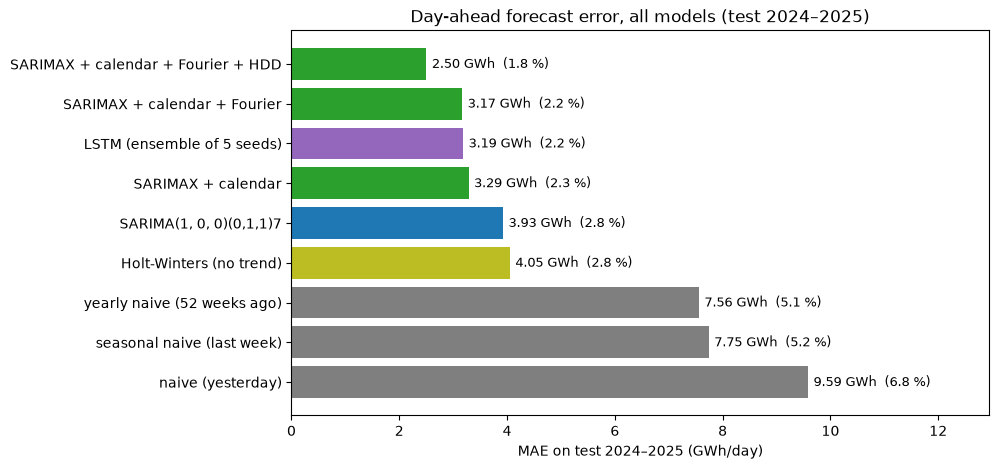

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG = "../figures/"
scores = pd.read_csv("../results/scores.csv")
board = (scores[scores["period"] == "test 2024–2025"]
         .set_index("model")[["MAE", "RMSE", "MAPE (%)"]].sort_values("MAE"))

family = {"naive": "baseline", "Holt": "smoothing", "SARIMA(": "SARIMA", "SARIMAX": "SARIMAX", "LSTM": "LSTM"}
colors = {"baseline": "tab:gray", "smoothing": "tab:olive", "SARIMA": "tab:blue", "SARIMAX": "tab:green", "LSTM": "tab:purple"}
fam = [next(f for k, f in family.items() if k in m) for m in board.index]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(board.index[::-1], board["MAE"][::-1], color=[colors[f] for f in fam[::-1]])
for i, (v, p) in enumerate(zip(board["MAE"][::-1], board["MAPE (%)"][::-1])):
    ax.text(v + 0.1, i, f"{v:.2f} GWh  ({p:.1f} %)", va="center", fontsize=9)
ax.set_xlabel("MAE on test 2024–2025 (GWh/day)")
ax.set_title("Day-ahead forecast error, all models (test 2024–2025)")
ax.set_xlim(0, board["MAE"].max() * 1.35)
fig.savefig(FIG + "final_leaderboard.png", dpi=150, bbox_inches="tight")
board.round(2)

In [2]:
df = pd.read_csv("../data/processed/dataset_features.csv", index_col="date", parse_dates=True)
y = df["consumption_gwh"]
preds = pd.concat([pd.read_csv(f"../results/{f}", index_col="date", parse_dates=True)
                   for f in ["pred_06_holtwinters.csv", "pred_07_sarimax.csv", "pred_08_lstm.csv"]], axis=1)
preds["actual"] = y[preds.index]
print(preds.shape, list(preds.columns))

(731, 8) ['Holt-Winters', 'seasonal naive', 'SARIMA(1, 0, 0)(0,1,1)7', 'SARIMAX + calendar', 'SARIMAX + calendar + Fourier', 'SARIMAX + calendar + Fourier + HDD', 'LSTM (ensemble)', 'actual']


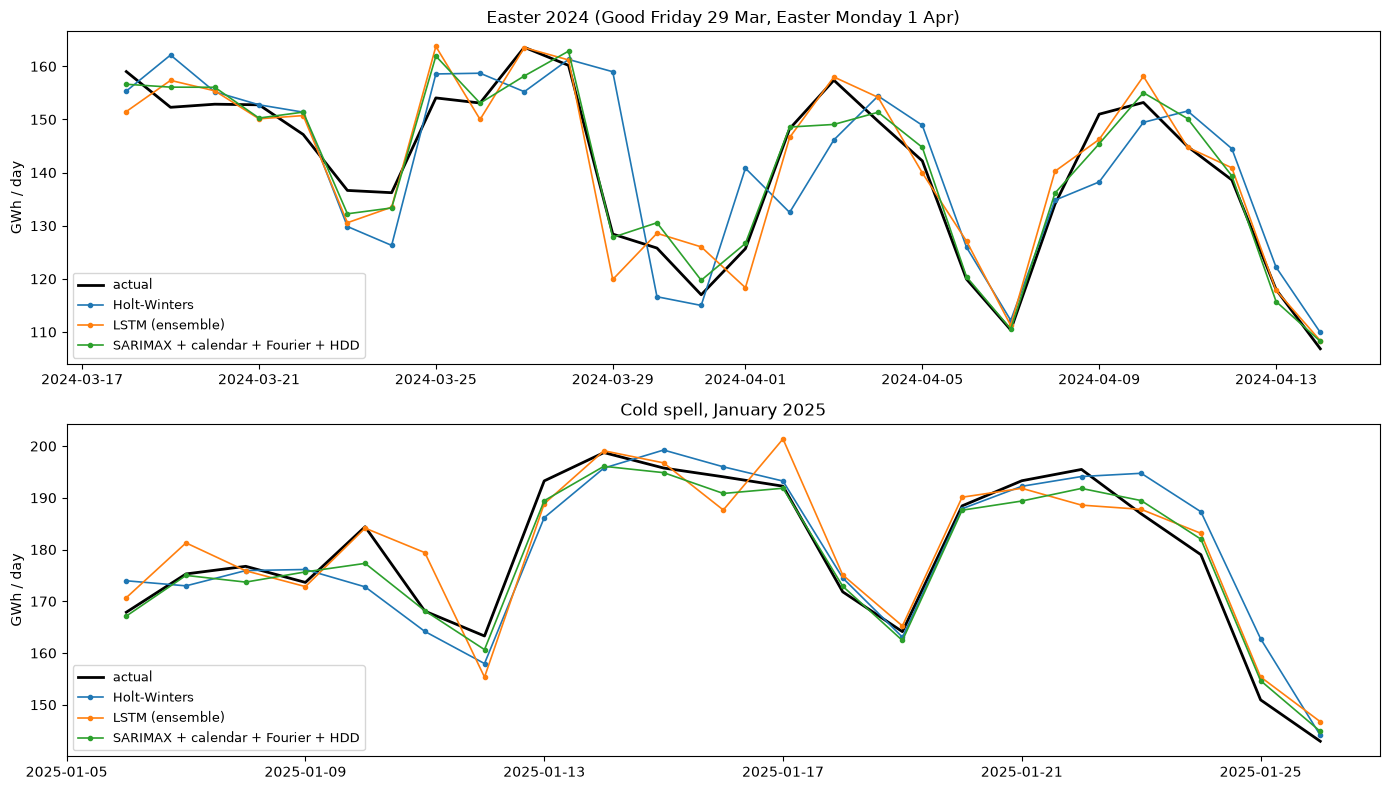

In [3]:
best = "SARIMAX + calendar + Fourier + HDD"
show = ["Holt-Winters", "LSTM (ensemble)", best]
windows = {"Easter 2024 (Good Friday 29 Mar, Easter Monday 1 Apr)": ("2024-03-18", "2024-04-14"),
           "Cold spell, January 2025": ("2025-01-06", "2025-01-26")}

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (title, (a, b)) in zip(axes, windows.items()):
    w = preds.loc[a:b]
    ax.plot(w.index, w["actual"], color="black", lw=2, label="actual")
    for c in show:
        ax.plot(w.index, w[c], lw=1.2, marker="o", ms=3, label=c)
    ax.set_title(title); ax.set_ylabel("GWh / day"); ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG + "final_zoom_easter_cold.png", dpi=150, bbox_inches="tight")

In [4]:
test = preds.index
day_type = pd.Series("normal weekday", index=test)
day_type[df.loc[test, "weekday"] >= 5] = "weekend"
day_type[df.loc[test, "christmas_period"] == 1] = "Christmas period"
day_type[df.loc[test, "bridge_day"] == 1] = "bridge day"
day_type[df.loc[test, "is_holiday"]] = "holiday"

models = ["seasonal naive", "Holt-Winters", "SARIMA(1, 0, 0)(0,1,1)7", "LSTM (ensemble)",
          "SARIMAX + calendar + Fourier", best]
abs_err = preds[models].sub(preds["actual"], axis=0).abs()
by_type = abs_err.groupby(day_type).mean().T.round(2)
by_type["days"] = None
counts = day_type.value_counts()
by_type = by_type[["normal weekday", "weekend", "holiday", "bridge day", "Christmas period"]]
print("days per type:", counts.to_dict())

winter = df.loc[test, "month"].isin([11, 12, 1, 2]).map({True: "winter (Nov–Feb)", False: "rest of year"})
by_season = abs_err.groupby(winter).mean().T.round(2)
display(by_type)
by_season

days per type: {'normal weekday': 493, 'weekend': 203, 'holiday': 18, 'Christmas period': 13, 'bridge day': 4}


,normal weekday,weekend,holiday,bridge day,Christmas period
seasonal naive,7.75,6.66,19.47,16.55,5.57
Holt-Winters,3.67,3.55,17.85,5.03,7.11
"SARIMA(1, 0, 0)(0,1,1)7",3.55,3.34,18.27,7.39,6.67
LSTM (ensemble),3.21,2.94,4.16,3.81,4.63
SARIMAX + calendar + Fourier,3.18,2.91,3.92,11.28,3.21
SARIMAX + calendar + Fourier + HDD,2.53,2.19,3.47,10.52,2.61


month,rest of year,winter (Nov–Feb)
seasonal naive,6.63,10.02
Holt-Winters,3.87,4.44
"SARIMA(1, 0, 0)(0,1,1)7",3.80,4.19
LSTM (ensemble),3.11,3.35
SARIMAX + calendar + Fourier,3.03,3.44
SARIMAX + calendar + Fourier + HDD,2.50,2.52


In [5]:
bridge = preds.index[df.loc[preds.index, "bridge_day"] == 1]
check = preds.loc[bridge, ["actual", "Holt-Winters", "LSTM (ensemble)", "SARIMAX + calendar + Fourier", best]].round(1)
check.insert(0, "day", bridge.strftime("%a"))
check["christmas_period"] = df.loc[bridge, "christmas_period"].values
check

,day,actual,Holt-Winters,LSTM (ensemble),SARIMAX + calendar + Fourier,SARIMAX + calendar + Fourier + HDD,christmas_period
date,,,,,,,
2024-05-10,Fri,120.7,119.8,129.1,132.6,130.2,0
2024-08-02,Fri,114.3,108.8,115.3,123.1,123.0,0
2024-12-27,Fri,168.1,156.1,164.7,154.5,154.2,1
2025-05-30,Fri,116.7,115.0,119.2,127.5,126.6,0


## Conclusion – Section 7

**Research question:** Can we accurately predict Swiss daily electricity consumption, and how much does temperature improve the forecast?

1. **Yes.** Day-ahead on 2024–2025 (731 unseen days), the best model, SARIMAX(1,0,0)(0,1,1)₇ with calendar, Fourier and HDD, reaches **MAE 2.50 GWh (1.75 %)**: a third of the seasonal-naive error (7.75) and 38 % below Holt-Winters (4.05).
2. **Calendar first.** Holidays are the largest errors for models without calendar knowledge (≈ 18 GWh per holiday); calendar features cut them by ≈ 80 %.
3. **Temperature second, and it matters.** Adding HDD cuts the error by 21 % overall, 27 % in winter. With HDD the winter penalty disappears (2.52 winter vs 2.50 rest of year). With a realistic 1 °C weather-forecast error the gain is still 14 %.
4. **More complex is not better here.** The LSTM ensemble (3.19) beats Holt-Winters and SARIMA but stays 27 % behind SARIMAX with HDD: the series' structure (fixed weekly shape, additive holiday and heating effects) is built into SARIMAX but must be learned by the LSTM from ~5,000 days.

**Limitations:** observed (not forecast) temperature; a single 4-station national temperature; overlapping calendar variables (e.g. bridge day inside the Christmas period); the 2022–23 structural break handled by differencing, not explained.

**Further work:** archived MeteoSwiss forecasts instead of observed temperature; population-weighted temperature; hybrid SARIMAX + LSTM on residuals; hourly day-ahead forecasting.